In [ ]:
import h5py
import numpy as np
import os
import pandas as pd

base = "/kaggle/input/datasets/tonylschmitz/digital-machining-database/"

# Already defined from previous run — redefine cleanly here
def load_stability_boundary(path):
    with h5py.File(path, "r") as f:
        key  = list(f.keys())[0]
        data = f[key][:]
    return data[:, 0], data[:, 1]

def load_time_file(filepath):
    with h5py.File(filepath, "r") as f:
        key  = list(f.keys())[0]
        data = f[key][:]
    td = data.T
    return {"omega": td[0,0], "b": td[1,0], "time": td[2,:],
            "xtpos": td[3,:],  "ytpos": td[4,:],
            "Forcex": td[15,:], "Forcey": td[16,:]}

def get_label(omega, b, omega_vec, blim_vec):
    idx = np.argmin(np.abs(omega_vec - omega))
    return 1 if b > blim_vec[idx] else 0

# ── LOAD ALL DATASET 1 RECORDS INTO A DATAFRAME ──────────────────────────────
ds1_path  = os.path.join(base, "Dataset 1 h5")
stab_path = os.path.join(ds1_path, "stability_boundary1.h5")
omega_vec, blim_vec = load_stability_boundary(stab_path)

time_files = sorted(
    [f for f in os.listdir(ds1_path) if f.startswith("time") and f.endswith(".h5")],
    key=lambda x: int(x.split("_")[1].replace(".h5",""))
)

records = []
for fname in time_files:
    fpath = os.path.join(ds1_path, fname)
    s     = load_time_file(fpath)
    idx   = np.argmin(np.abs(omega_vec - s["omega"]))
    blim  = blim_vec[idx]
    label = 1 if s["b"] > blim else 0
    records.append({
        "file"    : fname,
        "omega"   : s["omega"],
        "b_mm"    : round(s["b"] * 1000, 3),
        "blim_mm" : round(blim * 1000, 3),
        "label"   : label,
        "status"  : "UNSTABLE" if label == 1 else "STABLE"
    })

df = pd.DataFrame(records)

# ── 1. FULL OMEGA-B GRID AS A PIVOT TABLE ────────────────────────────────────
print("── Omega-B grid (0=stable, 1=unstable, blank=not sampled) ──")
pivot = df.pivot_table(
    index="b_mm",
    columns="omega",
    values="label",
    aggfunc="first"
)
# Show with b descending (high depth at top, like the stability lobe plot)
pivot = pivot.sort_index(ascending=False)
print(pivot.to_string())

# ── 2. AXIAL DEPTH COVERAGE PER SPINDLE SPEED ────────────────────────────────
print(f"\n── Axial depth values sampled per spindle speed ────")
for om in sorted(df["omega"].unique()):
    subset = df[df["omega"] == om].sort_values("b_mm")
    b_vals = subset["b_mm"].tolist()
    labels = subset["label"].tolist()
    pairs  = [f"{b}({'U' if l==1 else 'S'})" for b,l in zip(b_vals, labels)]
    print(f"  omega={om:>6.0f} rpm : {pairs}")

# ── 3. SUMMARY STATS ─────────────────────────────────────────────────────────
print(f"\n── Summary ─────────────────────────────────────────")
print(f"Unique spindle speeds : {df['omega'].nunique()}")
print(f"Unique axial depths   : {df['b_mm'].nunique()}")
print(f"b range               : {df['b_mm'].min()} – {df['b_mm'].max()} mm")
print(f"Stable files          : {(df['label']==0).sum()}")
print(f"Unstable files        : {(df['label']==1).sum()}")
print(f"Max b sampled         : {df['b_mm'].max()} mm")
print(f"Max blim in boundary  : {blim_vec.max()*1000:.3f} mm")

# ── 4. CLASS BALANCE ACROSS ALL 60 DATASETS ──────────────────────────────────
print(f"\n── Class balance across ALL 60 datasets ────────────")
print(f"{'DS':<6} {'Total':>7} {'Stable':>8} {'Unstable':>10} {'% Unstable':>12}")
print("-" * 48)

h5_folders = sorted(
    [f for f in os.listdir(base) if "h5" in f and "Dataset" in f],
    key=lambda x: int(x.replace("Dataset ", "").replace(" h5", ""))
)

all_stable, all_unstable = 0, 0
for folder in h5_folders:
    folder_path = os.path.join(base, folder)
    ds_num      = int(folder.replace("Dataset ", "").replace(" h5", ""))
    stab_file   = [f for f in os.listdir(folder_path) if f.startswith("stability")][0]
    ov, bv      = load_stability_boundary(os.path.join(folder_path, stab_file))
    t_files     = sorted(
        [f for f in os.listdir(folder_path) if f.startswith("time") and f.endswith(".h5")],
        key=lambda x: int(x.split("_")[1].replace(".h5",""))
    )
    n_s, n_u = 0, 0
    for fname in t_files:
        s = load_time_file(os.path.join(folder_path, fname))
        l = get_label(s["omega"], s["b"], ov, bv)
        if l == 1: n_u += 1
        else:      n_s += 1
    total      = n_s + n_u
    pct        = 100 * n_u / total if total > 0 else 0
    all_stable   += n_s
    all_unstable += n_u
    print(f"{ds_num:<6} {total:>7} {n_s:>8} {n_u:>10} {pct:>11.1f}%")

grand_total = all_stable + all_unstable
print("-" * 48)
print(f"{'ALL':<6} {grand_total:>7} {all_stable:>8} {all_unstable:>10} {100*all_unstable/grand_total:>11.1f}%")

══════════════════════════════════════════════════════════════════════
PART 1 — WHAT VARIES ACROSS 60 DATASETS
══════════════════════════════════════════════════════════════════════
Shape   : (480, 34)
Columns : ['Dataset', 'Mode number', 'fntx (Hz)', 'ktx (N/m)', 'zetatx', 'fnty (Hz)', 'kty (N/m)', 'zetaty', 'fnwx (Hz)', 'kwx (N/m)', 'zetawx', 'fnwy (Hz)', 'kwy (N/m)', 'zetawy', 'ktc (N/m2)', 'knc (N/m2)', 'kte (N/m)', 'kne (N/m)', 'Cn (N/m)', 'd (m)', 'm', 'beta (deg)', 'tooth_angle (deg)', 'RO (m)', 'et', 'ud', 'a (m)', 'ft_mean (m)', 'omega min (rpm)', 'omega max (rpm)', 'omega increment (rpm)', 'b min (m)', 'b increment (m)', 'Noise std (%)']

First 5 rows:
   Dataset  Mode number  fntx (Hz)  ktx (N/m)  zetatx  fnty (Hz)  kty (N/m)  zetaty  fnwx (Hz)     kwx (N/m)  zetawx  fnwy (Hz)     kwy (N/m)  zetawy   ktc (N/m2)   knc (N/m2)  kte (N/m)  kne (N/m)  Cn (N/m)   d (m)    m  beta (deg)  tooth_angle (deg)  RO (m)   et   ud     a (m)  ft_mean (m)  omega min (rpm)  omega max (rpm)  o

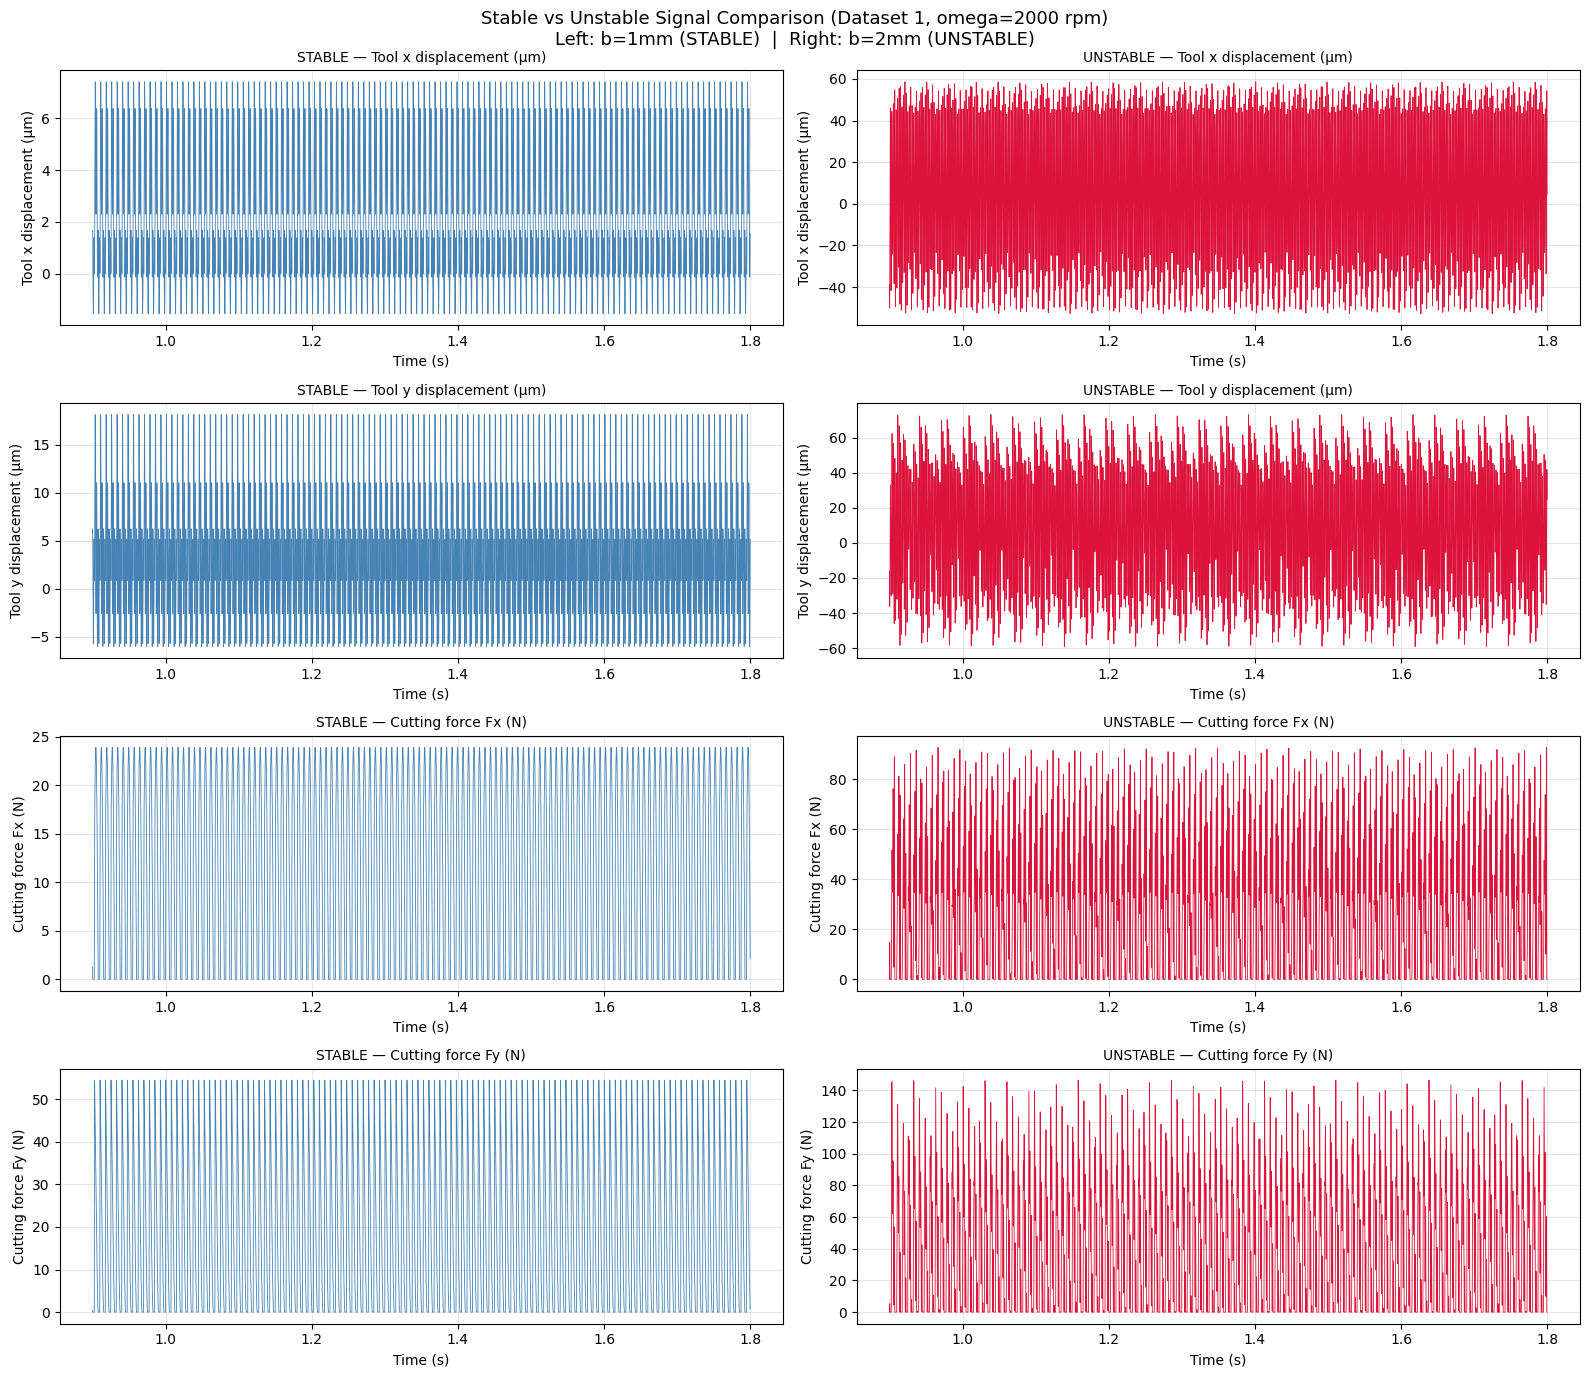

Saved: signal_comparison.png

══════════════════════════════════════════════════════════════════════
PART 3 — FFT ANALYSIS
══════════════════════════════════════════════════════════════════════
Tooth pass frequency : 133.33 Hz
Natural frequency    : 500 Hz (from dataset description)
Sampling frequency   : 12533.3 Hz

STABLE — xtpos top 5 frequencies:
      0.00 Hz  →  magnitude 0.000005
    133.33 Hz  →  magnitude 0.000003
    533.33 Hz  →  magnitude 0.000002
    400.00 Hz  →  magnitude 0.000001
    266.67 Hz  →  magnitude 0.000000

UNSTABLE — xtpos top 5 frequencies:
    502.22 Hz  →  magnitude 0.000044
      0.00 Hz  →  magnitude 0.000010
    133.33 Hz  →  magnitude 0.000006
    501.11 Hz  →  magnitude 0.000005
    635.56 Hz  →  magnitude 0.000005

STABLE — Forcex top 5 frequencies:
      0.00 Hz  →  magnitude 23.119464
    133.33 Hz  →  magnitude 13.343977
    400.00 Hz  →  magnitude 1.744484
    533.33 Hz  →  magnitude 1.294929
    266.67 Hz  →  magnitude 1.258237

UNSTABLE — Force

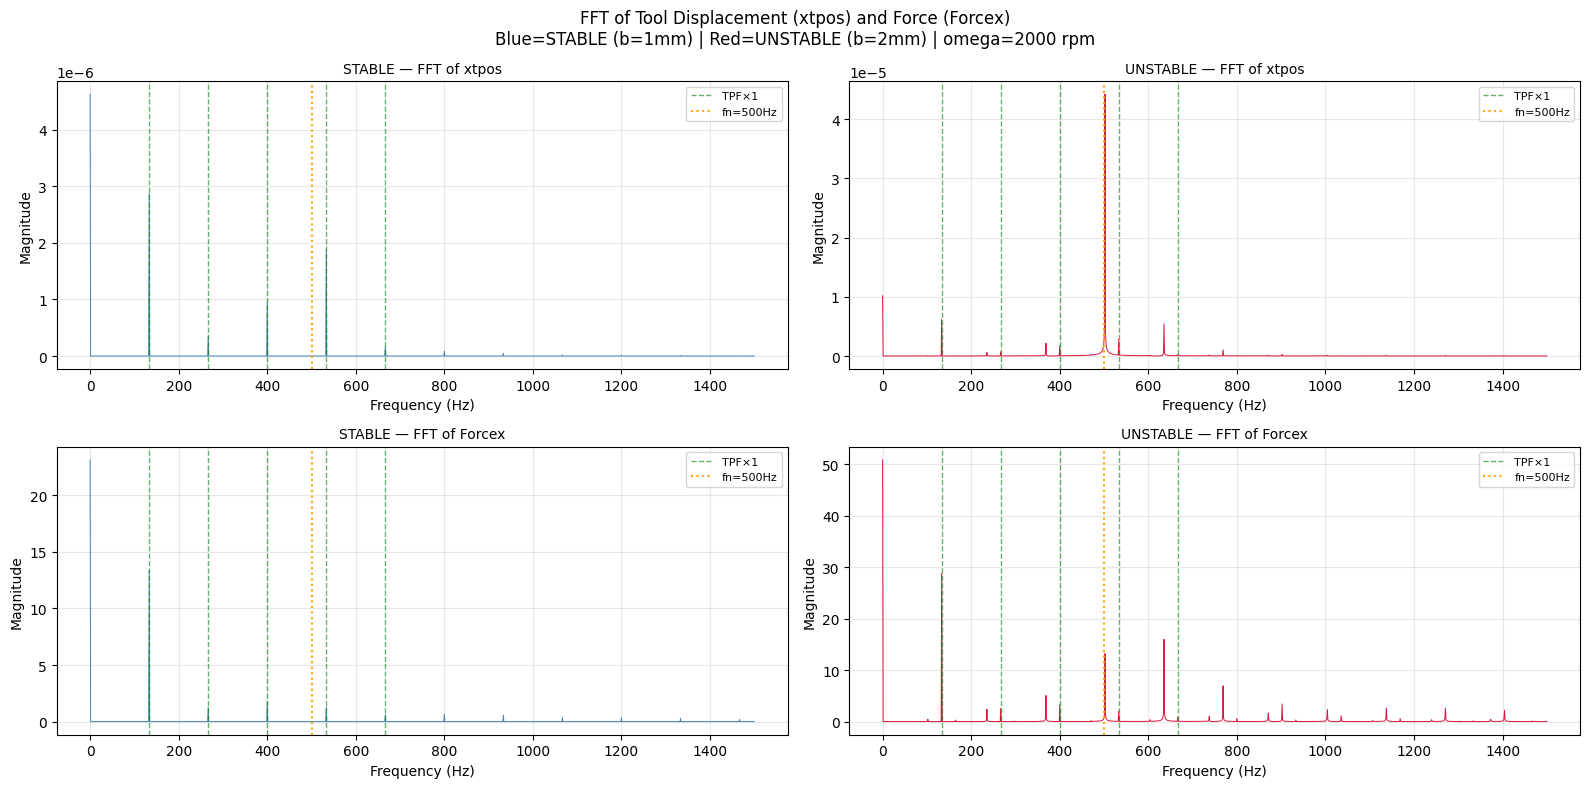


Saved: fft_comparison.png

══════════════════════════════════════════════════════════════════════
PART 4 — PHASE PORTRAITS
══════════════════════════════════════════════════════════════════════


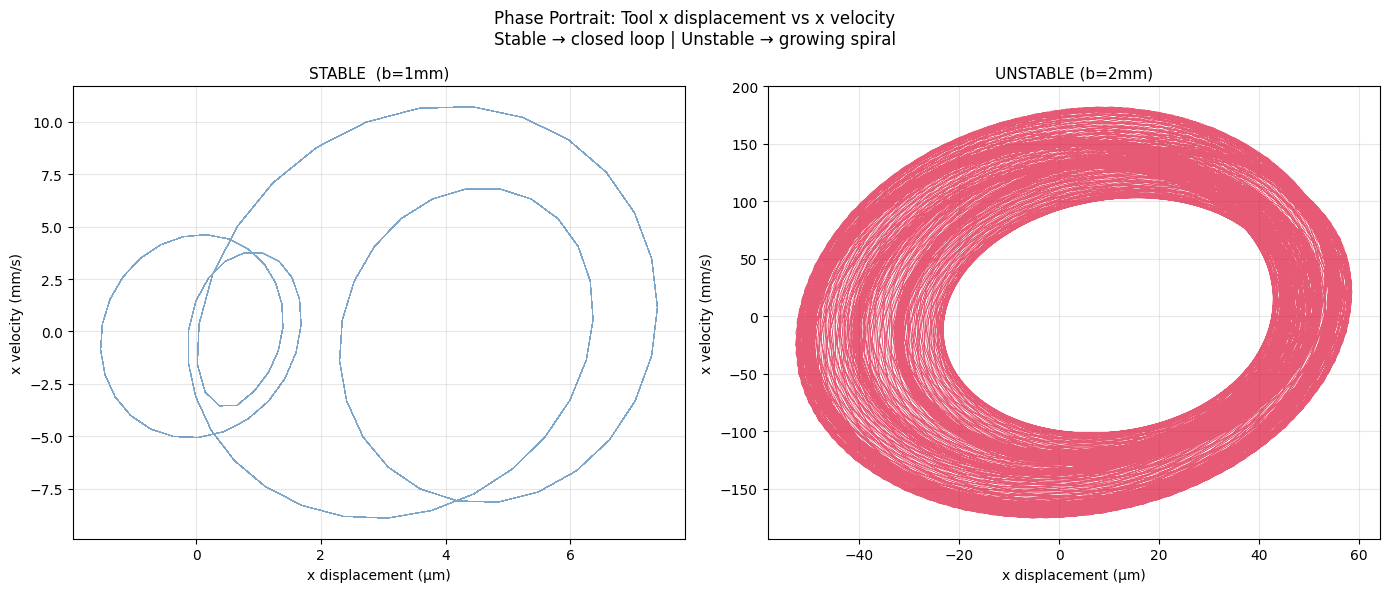

Saved: phase_portrait.png

══════════════════════════════════════════════════════════════════════
PART 5 — STATISTICAL SUMMARY ACROSS ALL DATASET 1 FILES
══════════════════════════════════════════════════════════════════════

── Mean statistics by class ────────────────────────
       xtpos_rms_um  xtpos_pp_um  xtpos_kurtosis  Forcex_rms_N  Forcex_pp_N  dom_freq_Hz  freq_ratio
label                                                                                               
0           49.5554     137.1829         -1.3977       54.7716      75.6481     471.1111      1.1000
1           58.8361     191.1797         -1.2666       70.8832     179.3523     492.5992      1.3456

── Key observations ────────────────────────────────
  xtpos_rms_um          : stable=49.555  unstable=58.836  ratio=1.19x
  xtpos_pp_um           : stable=137.183  unstable=191.180  ratio=1.39x
  Forcex_rms_N          : stable=54.772  unstable=70.883  ratio=1.29x
  xtpos_kurtosis        : stable=-1.398  unstable=-

In [6]:
import h5py
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as scipy_signal

base = "/kaggle/input/datasets/tonylschmitz/digital-machining-database/"

# ── REDEFINE HELPERS ──────────────────────────────────────────────────────────
def load_stability_boundary(path):
    with h5py.File(path, "r") as f:
        data = f[list(f.keys())[0]][:]
    return data[:, 0], data[:, 1]

def load_time_file(filepath):
    with h5py.File(filepath, "r") as f:
        data = f[list(f.keys())[0]][:].T   # (17, N)
    return {
        "omega" : data[0, 0],
        "b"     : data[1, 0],
        "time"  : data[2,  :],
        "xtpos" : data[3,  :],
        "ytpos" : data[4,  :],
        "xwpos" : data[5,  :],
        "ywpos" : data[6,  :],
        "xtvel" : data[7,  :],
        "ytvel" : data[8,  :],
        "xwvel" : data[9,  :],
        "ywvel" : data[10, :],
        "xtacc" : data[11, :],
        "ytacc" : data[12, :],
        "xwacc" : data[13, :],
        "ywacc" : data[14, :],
        "Forcex": data[15, :],
        "Forcey": data[16, :],
    }

def get_label(omega, b, omega_vec, blim_vec):
    return 1 if b > blim_vec[np.argmin(np.abs(omega_vec - omega))] else 0

# ═══════════════════════════════════════════════════════════════════════════════
# PART 1 — DATASET DESCRIPTIONS SPREADSHEET
# ═══════════════════════════════════════════════════════════════════════════════
print("═" * 70)
print("PART 1 — WHAT VARIES ACROSS 60 DATASETS")
print("═" * 70)

xlsx_path = os.path.join(base, "Dataset descriptions.xlsx")
desc      = pd.read_excel(xlsx_path)

print(f"Shape   : {desc.shape}")
print(f"Columns : {desc.columns.tolist()}")
print(f"\nFirst 5 rows:")
print(desc.head().to_string())
print(f"\nData types:\n{desc.dtypes}")

print(f"\n── Unique values per column ──────────────────────────")
for col in desc.columns:
    n_unique = desc[col].nunique()
    vals     = desc[col].dropna().unique()
    dtype    = desc[col].dtype

    if n_unique <= 6:
        print(f"  {col:<40} {n_unique} unique → {vals}")
    elif pd.api.types.is_numeric_dtype(dtype):
        print(f"  {col:<40} {n_unique} unique  range: {desc[col].min():.4g} – {desc[col].max():.4g}")
    else:
        print(f"  {col:<40} {n_unique} unique  samples: {list(vals[:3])}")

# ═══════════════════════════════════════════════════════════════════════════════
# PART 2 — SIGNAL VISUALIZATION: STABLE vs UNSTABLE SIDE BY SIDE
# ═══════════════════════════════════════════════════════════════════════════════
print("\n" + "═" * 70)
print("PART 2 — SIGNAL VISUALIZATION")
print("═" * 70)

ds1_path  = os.path.join(base, "Dataset 1 h5")
ov, bv    = load_stability_boundary(os.path.join(ds1_path, "stability_boundary1.h5"))

# Pick one stable and one unstable file at same spindle speed for fair comparison
# omega=4000: stable=time at b=1mm, unstable=time at b=3mm
stable_file   = os.path.join(ds1_path, "time1_1.h5")   # 2000 rpm, b=1mm  → stable
unstable_file = os.path.join(ds1_path, "time1_2.h5")   # 2000 rpm, b=2mm  → unstable

s_stable   = load_time_file(stable_file)
s_unstable = load_time_file(unstable_file)

# Use only the second half of signal (skip transient startup)
def trim_transient(sig, frac=0.5):
    """Keep only the last `frac` of the signal to skip startup transient."""
    n = len(sig["time"])
    start = int(n * frac)
    return {k: (v[start:] if hasattr(v, '__len__') and len(v) == n else v)
            for k, v in sig.items()}

s_st = trim_transient(s_stable)
s_un = trim_transient(s_unstable)

fig, axes = plt.subplots(4, 2, figsize=(16, 14))
fig.suptitle("Stable vs Unstable Signal Comparison (Dataset 1, omega=2000 rpm)\n"
             "Left: b=1mm (STABLE)  |  Right: b=2mm (UNSTABLE)", fontsize=13)

channels = [
    ("xtpos",  "Tool x displacement (µm)",  1e6),
    ("ytpos",  "Tool y displacement (µm)",  1e6),
    ("Forcex", "Cutting force Fx (N)",       1.0),
    ("Forcey", "Cutting force Fy (N)",       1.0),
]

for row, (ch, label, scale) in enumerate(channels):
    for col, (sig, title) in enumerate([(s_st, "STABLE"), (s_un, "UNSTABLE")]):
        ax = axes[row, col]
        ax.plot(sig["time"], sig[ch] * scale, linewidth=0.6,
                color="steelblue" if col == 0 else "crimson")
        ax.set_title(f"{title} — {label}", fontsize=10)
        ax.set_xlabel("Time (s)")
        ax.set_ylabel(label)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("signal_comparison.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: signal_comparison.png")

# ═══════════════════════════════════════════════════════════════════════════════
# PART 3 — FFT: FREQUENCY CONTENT STABLE vs UNSTABLE
# ═══════════════════════════════════════════════════════════════════════════════
print("\n" + "═" * 70)
print("PART 3 — FFT ANALYSIS")
print("═" * 70)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle("FFT of Tool Displacement (xtpos) and Force (Forcex)\n"
             "Blue=STABLE (b=1mm) | Red=UNSTABLE (b=2mm) | omega=2000 rpm", fontsize=12)

dt = s_stable["time"][1] - s_stable["time"][0]
fs = 1 / dt  # sampling frequency

# Tooth pass frequency
tooth_pass_freq = s_stable["omega"] * 4 / 60
print(f"Tooth pass frequency : {tooth_pass_freq:.2f} Hz")
print(f"Natural frequency    : 500 Hz (from dataset description)")
print(f"Sampling frequency   : {fs:.1f} Hz")

for row, ch in enumerate(["xtpos", "Forcex"]):
    for col, (sig, color, label) in enumerate([
        (s_st,  "steelblue", "STABLE"),
        (s_un,  "crimson",   "UNSTABLE")
    ]):
        ax      = axes[row, col]
        x       = sig[ch]
        n       = len(x)
        freqs   = np.fft.rfftfreq(n, d=dt)
        fft_mag = np.abs(np.fft.rfft(x)) * 2 / n

        # Only plot up to 1500 Hz (well above natural freq)
        mask = freqs <= 1500
        ax.plot(freqs[mask], fft_mag[mask], color=color, linewidth=0.7)

        # Mark tooth pass harmonics
        for k in range(1, 6):
            ax.axvline(tooth_pass_freq * k, color="green", linestyle="--",
                       alpha=0.6, linewidth=1, label=f"TPF×{k}" if k==1 else "")

        # Mark natural frequency
        ax.axvline(500, color="orange", linestyle=":", linewidth=1.5, label="fn=500Hz")

        ax.set_title(f"{label} — FFT of {ch}", fontsize=10)
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Magnitude")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

        # Print dominant frequencies
        top5_idx  = np.argsort(fft_mag[mask])[-5:][::-1]
        top5_freq = freqs[mask][top5_idx]
        top5_mag  = fft_mag[mask][top5_idx]
        print(f"\n{label} — {ch} top 5 frequencies:")
        for f, m in zip(top5_freq, top5_mag):
            print(f"  {f:>8.2f} Hz  →  magnitude {m:.6f}")

plt.tight_layout()
plt.savefig("fft_comparison.png", dpi=120, bbox_inches="tight")
plt.show()
print("\nSaved: fft_comparison.png")

# ═══════════════════════════════════════════════════════════════════════════════
# PART 4 — PHASE PORTRAIT (xtpos vs xtvel)
# ═══════════════════════════════════════════════════════════════════════════════
print("\n" + "═" * 70)
print("PART 4 — PHASE PORTRAITS")
print("═" * 70)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Phase Portrait: Tool x displacement vs x velocity\n"
             "Stable → closed loop | Unstable → growing spiral", fontsize=12)

for ax, (sig, color, label) in zip(axes, [
    (s_st,  "steelblue", "STABLE  (b=1mm)"),
    (s_un,  "crimson",   "UNSTABLE (b=2mm)")
]):
    ax.plot(sig["xtpos"]*1e6, sig["xtvel"]*1e3,
            color=color, linewidth=0.4, alpha=0.7)
    ax.set_xlabel("x displacement (µm)")
    ax.set_ylabel("x velocity (mm/s)")
    ax.set_title(label, fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("phase_portrait.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: phase_portrait.png")

# ═══════════════════════════════════════════════════════════════════════════════
# PART 5 — SIGNAL STATISTICS ACROSS ALL DATASET 1 FILES
# ═══════════════════════════════════════════════════════════════════════════════
print("\n" + "═" * 70)
print("PART 5 — STATISTICAL SUMMARY ACROSS ALL DATASET 1 FILES")
print("═" * 70)

time_files = sorted(
    [f for f in os.listdir(ds1_path) if f.startswith("time") and f.endswith(".h5")],
    key=lambda x: int(x.split("_")[1].replace(".h5",""))
)

rows = []
for fname in time_files:
    sig   = load_time_file(os.path.join(ds1_path, fname))
    label = get_label(sig["omega"], sig["b"], ov, bv)
    n     = len(sig["time"])
    start = n // 2    # skip transient

    xtpos_ss  = sig["xtpos"][start:]
    Forcex_ss = sig["Forcex"][start:]

    # FFT of xtpos in steady state
    freqs   = np.fft.rfftfreq(len(xtpos_ss), d=(sig["time"][1]-sig["time"][0]))
    fft_mag = np.abs(np.fft.rfft(xtpos_ss))
    dom_idx = np.argmax(fft_mag[1:]) + 1   # skip DC
    dom_freq = freqs[dom_idx]

    rows.append({
        "file"            : fname,
        "omega"           : sig["omega"],
        "b_mm"            : sig["b"] * 1000,
        "label"           : label,
        "xtpos_rms_um"    : np.sqrt(np.mean(xtpos_ss**2)) * 1e6,
        "xtpos_pp_um"     : (xtpos_ss.max() - xtpos_ss.min()) * 1e6,
        "xtpos_kurtosis"  : float(pd.Series(xtpos_ss).kurt()),
        "Forcex_rms_N"    : np.sqrt(np.mean(Forcex_ss**2)),
        "Forcex_pp_N"     : Forcex_ss.max() - Forcex_ss.min(),
        "dom_freq_Hz"     : dom_freq,
        "tooth_pass_Hz"   : sig["omega"] * 4 / 60,
        "freq_ratio"      : dom_freq / (sig["omega"] * 4 / 60),
    })

stats_df = pd.DataFrame(rows)

print("\n── Mean statistics by class ────────────────────────")
numeric_cols = ["xtpos_rms_um","xtpos_pp_um","xtpos_kurtosis",
                "Forcex_rms_N","Forcex_pp_N","dom_freq_Hz","freq_ratio"]
print(stats_df.groupby("label")[numeric_cols].mean().round(4).to_string())

print("\n── Key observations ────────────────────────────────")
for col in ["xtpos_rms_um", "xtpos_pp_um", "Forcex_rms_N", "xtpos_kurtosis"]:
    stable_mean   = stats_df[stats_df["label"]==0][col].mean()
    unstable_mean = stats_df[stats_df["label"]==1][col].mean()
    ratio         = unstable_mean / stable_mean if stable_mean != 0 else float("inf")
    print(f"  {col:<22}: stable={stable_mean:.3f}  unstable={unstable_mean:.3f}  "
          f"ratio={ratio:.2f}x")

print("\n── Dominant frequency: stable vs unstable ──────────")
print("  Stable dominant frequencies (should be tooth-pass harmonics):")
print(stats_df[stats_df["label"]==0][["omega","b_mm","dom_freq_Hz","tooth_pass_Hz","freq_ratio"]]
      .head(8).to_string(index=False))
print("\n  Unstable dominant frequencies (chatter peak near fn=500Hz):")
print(stats_df[stats_df["label"]==1][["omega","b_mm","dom_freq_Hz","tooth_pass_Hz","freq_ratio"]]
      .head(8).to_string(index=False))

In [32]:
"""
==============================================================================
Digital Machining Database — Preprocessing & EDA Pipeline (v3)
MDP PRISM Project | University of Michigan
==============================================================================

Kaggle data structure:
  - Folders: "Dataset X h5" (with spaces)
  - Each .h5 file has ONE key (e.g. 'time1_1') containing a (22560, 17) array
  - Column order: omega, b, time, xtpos, ytpos, xwpos, ywpos, xtvel, ytvel,
                  xwvel, ywvel, xtacc, ytacc, xwacc, ywacc, Forcex, Forcey
  - Boundary files: "stability_boundaryX.h5" with shape (10001, 2):
                    col0 = omega (RPM), col1 = blim (metres)
  - Metadata: "Dataset descriptions.xlsx" with multi-row entries per dataset

Requirements:
  pip install h5py numpy pandas scipy matplotlib seaborn scikit-learn openpyxl
"""

import os
import glob
import warnings
import h5py
import numpy as np
import pandas as pd
from scipy.signal import welch
from scipy.stats import kurtosis, entropy as sp_entropy
from scipy.interpolate import interp1d
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ============================================================================
# 1. CONFIGURATION
# ============================================================================

DATA_DIR = "/kaggle/input/datasets/tonylschmitz/digital-machining-database"
METADATA_PATH = os.path.join(DATA_DIR, "Dataset descriptions.xlsx")

DATASET_IDS = list(range(1, 61))  # Only original 60; 61-120 are noisy repeats

N_STEPS = 22560
T_TOTAL = 1.8
FS = N_STEPS / T_TOTAL  # ~12533.3 Hz

NPERSEG = 2048  # Welch PSD segment length

# Column indices for the (22560, 17) array
COL = {
    "omega": 0, "b": 1, "time": 2,
    "xtpos": 3, "ytpos": 4, "xwpos": 5, "ywpos": 6,
    "xtvel": 7, "ytvel": 8, "xwvel": 9, "ywvel": 10,
    "xtacc": 11, "ytacc": 12, "xwacc": 13, "ywacc": 14,
    "Forcex": 15, "Forcey": 16,
}

FEATURES_CSV = "features_all_datasets.csv"
PLOTS_DIR = "eda_plots"
os.makedirs(PLOTS_DIR, exist_ok=True)


# ============================================================================
# 2. FOLDER DISCOVERY
# ============================================================================

def get_dataset_folder(ds_id):
    candidates = [
        os.path.join(DATA_DIR, f"Dataset {ds_id} h5"),
        os.path.join(DATA_DIR, f"Dataset_{ds_id}"),
        os.path.join(DATA_DIR, f"Dataset_{ds_id}_h5"),
        os.path.join(DATA_DIR, f"dataset {ds_id} h5"),
    ]
    for path in candidates:
        if os.path.isdir(path):
            return path
    return None


# ============================================================================
# 3. BOUNDARY LOADING & INTERPOLATION
# ============================================================================

def find_boundary_file(folder):
    all_h5 = sorted(glob.glob(os.path.join(folder, "*.h5")))
    for f in all_h5:
        base = os.path.basename(f).lower()
        if any(kw in base for kw in ["boundary", "blim", "stability", "stab"]):
            return f
    for f in all_h5:
        if os.path.basename(f).lower().startswith("time"):
            continue
        return f  # First non-time file
    return None


def load_boundary(folder):
    bf = find_boundary_file(folder)
    if bf is None:
        return None
    with h5py.File(bf, "r") as hf:
        key = list(hf.keys())[0]
        data = np.array(hf[key])
    if data.ndim == 1:
        return None
    omega_b = data[:, 0].flatten()
    blim_b = data[:, 1].flatten()
    if np.nanmax(blim_b) < 0.1:
        blim_b = blim_b * 1000.0
    interp_fn = interp1d(omega_b, blim_b, kind="linear",
                         fill_value="extrapolate", assume_sorted=False)
    return interp_fn


# ============================================================================
# 4. FEATURE EXTRACTION
# ============================================================================

def time_features(sig):
    rms = np.sqrt(np.mean(sig ** 2))
    ptp = np.ptp(sig)
    kurt = kurtosis(sig, fisher=True)
    peak = np.max(np.abs(sig))
    crest = peak / rms if rms > 0 else 0.0
    mean_centered = sig - np.mean(sig)
    zcr = np.sum(np.diff(np.sign(mean_centered)) != 0) / len(sig)
    return rms, ptp, kurt, crest, zcr


def freq_features(sig, fs, tpf, fn, n_harmonics=4):
    freqs, psd = welch(sig, fs, nperseg=NPERSEG)
    total_energy = np.sum(psd)
    if total_energy == 0:
        return 0, 0, 0, 0, 0, 0, 0

    dom_idx = np.argmax(psd)
    f_dom = freqs[dom_idx]
    freq_ratio_tpf = f_dom / tpf if tpf > 0 else 0
    fn_proximity = abs(f_dom - fn) / fn if fn > 0 else 0

    bw = 0.10
    tpf_band = (freqs > tpf * (1 - bw)) & (freqs < tpf * (1 + bw))
    chatter_band = (freqs > fn * (1 - bw)) & (freqs < fn * (1 + bw))
    e_tpf = np.sum(psd[tpf_band])
    e_chatter = np.sum(psd[chatter_band])
    energy_ratio = e_chatter / e_tpf if e_tpf > 0 else 0

    harmonic_energy = 0.0
    for h in range(1, n_harmonics + 1):
        fc = tpf * h
        band = (freqs > fc * (1 - bw)) & (freqs < fc * (1 + bw))
        harmonic_energy += np.sum(psd[band])
    harmonic_energy_ratio = harmonic_energy / total_energy

    sideband_energy = 0.0
    for offset in [tpf, -tpf, 2 * tpf, -2 * tpf]:
        fc = f_dom + offset
        if fc > 0:
            band = (freqs > fc * (1 - bw)) & (freqs < fc * (1 + bw))
            sideband_energy += np.sum(psd[band])
    sideband_energy_norm = sideband_energy / total_energy

    psd_norm = psd / total_energy
    psd_norm = psd_norm[psd_norm > 0]
    spec_entropy = sp_entropy(psd_norm)

    return (freq_ratio_tpf, fn_proximity, energy_ratio,
            harmonic_energy_ratio, sideband_energy_norm, spec_entropy, f_dom)


CHANNELS_TIME = ["xtpos", "ytpos", "Forcex", "Forcey", "xtvel", "ytvel"]
CHANNELS_FREQ = ["xtpos", "ytpos", "Forcex", "Forcey"]
TIME_FEAT_NAMES = ["rms", "ptp", "kurt", "crest", "zcr"]
FREQ_FEAT_NAMES = ["freq_ratio_tpf", "fn_proximity", "energy_ratio",
                   "harmonic_energy_ratio", "sideband_energy",
                   "spectral_entropy", "dominant_freq"]


def extract_signal_features(data_array, tpf, fn):
    row = {}
    for ch in CHANNELS_TIME:
        if ch not in COL:
            for name in TIME_FEAT_NAMES:
                row[f"{ch}_{name}"] = np.nan
            continue
        sig = data_array[:, COL[ch]]
        feats = time_features(sig)
        for name, val in zip(TIME_FEAT_NAMES, feats):
            row[f"{ch}_{name}"] = val

    for ch in CHANNELS_FREQ:
        if ch not in COL:
            for name in FREQ_FEAT_NAMES:
                row[f"{ch}_{name}"] = np.nan
            continue
        sig = data_array[:, COL[ch]]
        feats = freq_features(sig, FS, tpf, fn)
        for name, val in zip(FREQ_FEAT_NAMES, feats):
            row[f"{ch}_{name}"] = val

    return row


# ============================================================================
# 5. METADATA LOADING
# ============================================================================

def load_metadata(path):
    if not os.path.exists(path):
        for root, dirs, files in os.walk(DATA_DIR):
            for f in files:
                if "description" in f.lower() and f.endswith(".xlsx"):
                    path = os.path.join(root, f)
                    break
    if not os.path.exists(path):
        print("[WARN] Metadata spreadsheet not found. Using defaults.")
        return {}

    df = pd.read_excel(path)
    print(f"  Metadata loaded: {len(df)} rows, columns: {df.columns.tolist()[:8]}...")

    df["Dataset"] = df["Dataset"].ffill()
    df_first = df.groupby("Dataset").first().reset_index()

    meta = {}
    for _, r in df_first.iterrows():
        ds_id = int(r["Dataset"])
        fn = float(r.get("fntx (Hz)", np.nan))
        ktc = float(r.get("ktc (N/m2)", np.nan))
        teeth = int(r.get("m", 4)) if not pd.isna(r.get("m")) else 4
        damping = float(r.get("Cn (N/m)", 0.0))
        if pd.isna(damping):
            damping = 0.0
        cut_dir = int(r.get("ud", 1)) if not pd.isna(r.get("ud")) else 1
        d_m = float(r.get("d (m)", 0.0127))
        diameter_mm = d_m * 1000 if (not pd.isna(d_m) and d_m < 1) else d_m
        ktx = float(r.get("ktx (N/m)", np.nan))
        zetatx = float(r.get("zetatx", np.nan))
        fnty = float(r.get("fnty (Hz)", np.nan))
        ro = float(r.get("RO (m)", 0.0))
        if pd.isna(ro):
            ro = 0.0
        noise_std = float(r.get("Noise std (%)", 0.0))
        if pd.isna(noise_std):
            noise_std = 0.0

        meta[ds_id] = {
            "fn": fn, "ktc": ktc, "teeth": teeth, "damping": damping,
            "cut_dir": cut_dir, "diameter_mm": diameter_mm, "ktx": ktx,
            "zetatx": zetatx, "fnty": fnty, "ro": ro, "noise_std": noise_std,
        }

    print(f"  Parsed metadata for {len(meta)} datasets")
    return meta


# ============================================================================
# 6. MAIN PROCESSING LOOP
# ============================================================================

def process_all_datasets():
    metadata = load_metadata(METADATA_PATH)
    all_rows = []
    skipped = 0
    boundary_missing = 0

    for ds_id in DATASET_IDS:
        folder = get_dataset_folder(ds_id)
        if folder is None:
            print(f"  [SKIP] Dataset {ds_id}: folder not found")
            skipped += 1
            continue

        blim_fn = load_boundary(folder)
        if blim_fn is None:
            boundary_missing += 1
            print(f"  [WARN] Dataset {ds_id}: no boundary file, labelling disabled")

        m = metadata.get(ds_id, {})
        fn = m.get("fn", np.nan)
        ktc = m.get("ktc", np.nan)
        teeth = m.get("teeth", 4)
        damping = m.get("damping", 0.0)
        cut_dir = m.get("cut_dir", 1)
        diameter_mm = m.get("diameter_mm", 12.7)
        ktx = m.get("ktx", np.nan)
        zetatx = m.get("zetatx", np.nan)
        fnty = m.get("fnty", np.nan)
        ro = m.get("ro", 0.0)
        noise_std = m.get("noise_std", 0.0)

        all_h5 = sorted(glob.glob(os.path.join(folder, "*.h5")))
        time_files = [f for f in all_h5
                      if os.path.basename(f).lower().startswith("time")]
        if not time_files:
            bf = find_boundary_file(folder)
            time_files = [f for f in all_h5 if f != bf]

        print(f"  Dataset {ds_id:>2d}: {len(time_files)} files, fn={fn}, "
              f"teeth={teeth}, boundary={'OK' if blim_fn else 'MISSING'}")

        for filepath in time_files:
            fname = os.path.basename(filepath)
            try:
                with h5py.File(filepath, "r") as hf:
                    key = list(hf.keys())[0]
                    data = np.array(hf[key])

                    omega = float(data[0, COL["omega"]])
                    b_raw = float(data[0, COL["b"]])
                    b_mm = b_raw * 1000.0 if b_raw < 0.1 else b_raw

                    if blim_fn is not None:
                        blim = float(blim_fn(omega))
                        label = 1 if b_mm > blim else 0
                        b_over_blim = b_mm / blim if blim > 0 else np.nan
                    else:
                        blim = np.nan
                        label = np.nan
                        b_over_blim = np.nan

                    tpf = (omega * teeth) / 60.0
                    tau = 60.0 / (omega * teeth) if (omega * teeth) > 0 else np.nan

                    sig_feats = extract_signal_features(data, tpf, fn)

                    norm_xtpos_rms = (
                        sig_feats.get("xtpos_rms", 0) * ktc
                        if not np.isnan(ktc) else np.nan
                    )
                    norm_ytpos_rms = (
                        sig_feats.get("ytpos_rms", 0) * ktc
                        if not np.isnan(ktc) else np.nan
                    )
                    norm_Forcex_rms = (
                        sig_feats.get("Forcex_rms", 0) / ktc
                        if (not np.isnan(ktc) and ktc > 0) else np.nan
                    )
                    norm_Forcey_rms = (
                        sig_feats.get("Forcey_rms", 0) / ktc
                        if (not np.isnan(ktc) and ktc > 0) else np.nan
                    )

                    row = {
                        "dataset": ds_id,
                        "file": fname,
                        "omega": omega,
                        "b_mm": b_mm,
                        "blim": blim,
                        "b_over_blim": b_over_blim,
                        "label": label,
                        "fn": fn,
                        "ktc": ktc,
                        "teeth": teeth,
                        "damping": damping,
                        "cut_dir": cut_dir,
                        "diameter_mm": diameter_mm,
                        "tpf": tpf,
                        "tau": tau,
                        "ktx": ktx,
                        "zetatx": zetatx,
                        "fnty": fnty,
                        "ro": ro,
                        "noise_std": noise_std,
                        "norm_xtpos_rms": norm_xtpos_rms,
                        "norm_ytpos_rms": norm_ytpos_rms,
                        "norm_Forcex_rms": norm_Forcex_rms,
                        "norm_Forcey_rms": norm_Forcey_rms,
                    }
                    row.update(sig_feats)
                    all_rows.append(row)

            except Exception as e:
                print(f"    [ERROR] {fname}: {e}")

    print(f"\nDone. Processed {len(all_rows)} files across "
          f"{len(DATASET_IDS) - skipped} datasets "
          f"({boundary_missing} without boundaries, {skipped} not found).")
    df = pd.DataFrame(all_rows)
    return df


# ============================================================================
# 7. EDA SUITE
# ============================================================================

def run_eda(df):
    if len(df) == 0 or "label" not in df.columns:
        print("[ERROR] No data to plot. Aborting EDA.")
        return

    df_labelled = df.dropna(subset=["label"]).copy()
    df_labelled["label"] = df_labelled["label"].astype(int)

    if len(df_labelled) == 0:
        print("[ERROR] No labelled data. Check boundary files.")
        return

    print(f"  Running EDA on {len(df_labelled)} labelled rows "
          f"({len(df) - len(df_labelled)} unlabelled dropped)")

    sns.set_theme(style="whitegrid", font_scale=1.1)
    label_map = {0: "Stable", 1: "Unstable"}
    palette = {0: "#2196F3", 1: "#F44336"}

    palette_str = {"0": "#2196F3", "1": "#F44336"}

    # 7.1 Class balance
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    counts = df_labelled["label"].value_counts().sort_index()
    axes[0].bar([label_map[i] for i in counts.index], counts.values,
                color=[palette[i] for i in counts.index], edgecolor="black")
    for i, v in enumerate(counts.values):
        axes[0].text(i, v + 50, f"{v}\n({v / len(df_labelled) * 100:.1f}%)",
                     ha="center", fontsize=11)
    axes[0].set_title("Overall Class Balance (Datasets 1-60)", fontsize=13)
    axes[0].set_ylabel("Count")

    ds_balance = df_labelled.groupby("dataset")["label"].mean() * 100
    axes[1].bar(ds_balance.index, ds_balance.values,
                color="#FF9800", edgecolor="black", linewidth=0.3)
    axes[1].axhline(50, color="red", ls="--", lw=1, label="50%")
    axes[1].set_xlabel("Dataset ID")
    axes[1].set_ylabel("% Unstable")
    axes[1].set_title("Unstable % by Dataset", fontsize=13)
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "01_class_balance.png"), dpi=150)
    plt.close()
    print("  [SAVED] 01_class_balance.png")

    # 7.2 Correlation matrix
    exclude = {"dataset", "label", "omega", "b_mm", "blim", "fn", "ktc",
               "teeth", "damping", "cut_dir", "diameter_mm", "tpf", "tau",
               "ktx", "zetatx", "fnty", "ro", "noise_std", "file"}
    feat_cols = [c for c in df_labelled.select_dtypes(include=[np.number]).columns
                 if c not in exclude]

    if len(feat_cols) >= 2:
        label_corr = (df_labelled[feat_cols]
                      .corrwith(df_labelled["label"]).abs()
                      .sort_values(ascending=False))
        top_feats = label_corr.head(20).index.tolist()
        corr = df_labelled[top_feats + ["label"]].corr()
        fig, ax = plt.subplots(figsize=(14, 12))
        mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
        sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
                    vmin=-1, vmax=1, linewidths=0.5, ax=ax,
                    cbar_kws={"shrink": 0.8})
        ax.set_title("Correlation Matrix — Top 20 Features + Label", fontsize=14)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "02_correlation_matrix.png"), dpi=150)
        plt.close()
        print("  [SAVED] 02_correlation_matrix.png")
    else:
        label_corr = pd.Series(dtype=float)

    # 7.3 Mutual information ranking
    feat_df = df_labelled[feat_cols].copy()
    feat_df = feat_df.replace([np.inf, -np.inf], np.nan).fillna(0)
    mi = mutual_info_classif(feat_df, df_labelled["label"],
                             random_state=42, n_neighbors=5)
    mi_series = pd.Series(mi, index=feat_cols).sort_values(ascending=False).head(25)

    fig, ax = plt.subplots(figsize=(10, 8))
    mi_series.plot.barh(ax=ax, color="#4CAF50", edgecolor="black")
    ax.invert_yaxis()
    ax.set_xlabel("Mutual Information (bits)")
    ax.set_title("Top 25 Features by Mutual Information with Label", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "03_mutual_information.png"), dpi=150)
    plt.close()
    print("  [SAVED] 03_mutual_information.png")

    # 7.4 Density: freq_ratio_tpf
    fr_col = "xtpos_freq_ratio_tpf"
    if fr_col in df_labelled.columns:
        fig, ax = plt.subplots(figsize=(10, 6))
        for lab, color in palette.items():
            subset = df_labelled[df_labelled["label"] == lab][fr_col].dropna()
            subset = subset[(subset > -2) & (subset < 15)]
            ax.hist(subset, bins=120, density=True, alpha=0.5,
                    color=color, label=label_map[lab])
        ax.set_xlabel("Frequency Ratio (Dominant Freq / TPF)")
        ax.set_ylabel("Density")
        ax.set_title("Frequency Ratio Distribution — Stable vs Unstable (xtpos)",
                      fontsize=13)
        ax.legend(fontsize=12)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "04_freq_ratio_density.png"), dpi=150)
        plt.close()
        print("  [SAVED] 04_freq_ratio_density.png")

    # 7.5 Box plots
    key_features = [
        "xtpos_rms", "ytpos_rms", "xtpos_kurt", "xtpos_crest",
        "Forcex_rms", "Forcey_rms",
        "xtpos_freq_ratio_tpf", "xtpos_energy_ratio",
        "xtpos_harmonic_energy_ratio", "xtpos_sideband_energy",
        "xtpos_spectral_entropy", "b_over_blim",
    ]
    key_features = [f for f in key_features if f in df_labelled.columns]

    if key_features:
        n = len(key_features)
        ncols = 3
        nrows = (n + ncols - 1) // ncols
        fig, axes_box = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
        axes_box = axes_box.flatten()
        for i, feat in enumerate(key_features):
            sub = df_labelled[[feat, "label"]].dropna()
            lo, hi = sub[feat].quantile(0.01), sub[feat].quantile(0.99)
            sub = sub[(sub[feat] >= lo) & (sub[feat] <= hi)]
            sns.boxplot(data=sub, x="label", y=feat, hue="label",
                        ax=axes_box[i],width=0.5, legend=False)
            axes_box[i].set_xticklabels(["Stable", "Unstable"])
            axes_box[i].set_title(feat, fontsize=11)
            axes_box[i].set_xlabel("")
        for j in range(i + 1, len(axes_box)):
            axes_box[j].set_visible(False)
        fig.suptitle("Feature Distributions by Stability Label",
                      fontsize=15, y=1.01)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "05_boxplots_key_features.png"),
                    dpi=150, bbox_inches="tight")
        plt.close()
        print("  [SAVED] 05_boxplots_key_features.png")

    # 7.6 Scatter: freq_ratio vs energy_ratio
    er_col = "xtpos_energy_ratio"
    if fr_col in df_labelled.columns and er_col in df_labelled.columns:
        fig, ax = plt.subplots(figsize=(10, 7))
        for lab, color in palette.items():
            sub = df_labelled[df_labelled["label"] == lab]
            ax.scatter(sub[fr_col], sub[er_col], c=color, alpha=0.3, s=8,
                       label=label_map[lab], edgecolors="none")
        ax.set_xlabel("Frequency Ratio (xtpos)")
        ax.set_ylabel("Energy Ratio (chatter band / TPF band)")
        ax.set_title("Frequency Ratio vs Energy Ratio — Separation Check",
                      fontsize=13)
        ax.legend(markerscale=4, fontsize=12)
        ax.set_xlim(0, 15)
        er_99 = df_labelled[er_col].quantile(0.99)
        if not np.isnan(er_99) and er_99 > 0:
            ax.set_ylim(0, er_99)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "06_scatter_freqratio_energyratio.png"),
                    dpi=150)
        plt.close()
        print("  [SAVED] 06_scatter_freqratio_energyratio.png")

    # 7.7 Spectral entropy vs harmonic energy ratio
    he_col = "xtpos_harmonic_energy_ratio"
    se_col = "xtpos_spectral_entropy"
    if he_col in df_labelled.columns and se_col in df_labelled.columns:
        fig, ax = plt.subplots(figsize=(10, 7))
        for lab, color in palette.items():
            sub = df_labelled[df_labelled["label"] == lab]
            ax.scatter(sub[he_col], sub[se_col], c=color, alpha=0.3, s=8,
                       label=label_map[lab], edgecolors="none")
        ax.set_xlabel("Harmonic Energy Ratio (xtpos)")
        ax.set_ylabel("Spectral Entropy (xtpos)")
        ax.set_title("Harmonic Energy Ratio vs Spectral Entropy", fontsize=13)
        ax.legend(markerscale=4, fontsize=12)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "07_scatter_harmonic_entropy.png"),
                    dpi=150)
        plt.close()
        print("  [SAVED] 07_scatter_harmonic_entropy.png")

    # 7.8 Feature generalisability: per-dataset means
    gen_feats = ["xtpos_freq_ratio_tpf", "xtpos_spectral_entropy",
                 "xtpos_harmonic_energy_ratio", "norm_xtpos_rms"]
    gen_feats = [f for f in gen_feats if f in df_labelled.columns]
    if gen_feats:
        fig, axes_gen = plt.subplots(len(gen_feats), 1,
                                      figsize=(14, 4 * len(gen_feats)), sharex=True)
        if len(gen_feats) == 1:
            axes_gen = [axes_gen]
        for ax, feat in zip(axes_gen, gen_feats):
            means = (df_labelled.groupby(["dataset", "label"])[feat]
                     .mean().unstack(fill_value=0))
            x = means.index
            if 0 in means.columns:
                ax.bar(x - 0.2, means[0], width=0.4,
                       color=palette[0], label="Stable")
            if 1 in means.columns:
                ax.bar(x + 0.2, means[1], width=0.4,
                       color=palette[1], label="Unstable")
            ax.set_ylabel(feat, fontsize=10)
            ax.legend(fontsize=9)
        axes_gen[-1].set_xlabel("Dataset ID")
        fig.suptitle("Feature Means by Dataset — Generalisability Check",
                      fontsize=14, y=1.0)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "08_feature_generalisability.png"),
                    dpi=150, bbox_inches="tight")
        plt.close()
        print("  [SAVED] 08_feature_generalisability.png")

    # 7.9 b/blim distribution
    if "b_over_blim" in df_labelled.columns:
        fig, ax = plt.subplots(figsize=(10, 6))
        for lab, color in palette.items():
            sub = df_labelled[df_labelled["label"] == lab]["b_over_blim"].dropna()
            sub = sub[sub < 5]
            ax.hist(sub, bins=80, density=True, alpha=0.5,
                    color=color, label=label_map[lab])
        ax.axvline(1.0, color="black", ls="--", lw=1.5,
                   label="Boundary (b/blim = 1)")
        ax.set_xlabel("b / blim")
        ax.set_ylabel("Density")
        ax.set_title("Distance from Stability Boundary", fontsize=13)
        ax.legend(fontsize=12)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOTS_DIR, "09_b_over_blim.png"), dpi=150)
        plt.close()
        print("  [SAVED] 09_b_over_blim.png")

    # 7.10 Process damping effect
    df_labelled["has_damping"] = df_labelled["damping"].apply(
        lambda x: "With Damping" if x > 0 else "No Damping")
    fig, axes_damp = plt.subplots(1, 2, figsize=(14, 5))
    for i, group in enumerate(["No Damping", "With Damping"]):
        sub = df_labelled[df_labelled["has_damping"] == group]
        if len(sub) == 0:
            continue
        pct = sub["label"].mean() * 100
        axes_damp[0].bar(i, pct, color=["#2196F3", "#FF9800"][i],
                         edgecolor="black")
        axes_damp[0].text(i, pct + 1, f"{pct:.1f}%", ha="center", fontsize=12)
    axes_damp[0].set_xticks([0, 1])
    axes_damp[0].set_xticklabels(["No Damping", "With Damping"])
    axes_damp[0].set_ylabel("% Unstable")
    axes_damp[0].set_title("Class Balance: Damping Effect")
    if fr_col in df_labelled.columns:
        for group, color in [("No Damping", "#2196F3"), ("With Damping", "#FF9800")]:
            sub = df_labelled[
                (df_labelled["has_damping"] == group) &
                (df_labelled["label"] == 1)
            ][fr_col].dropna()
            sub = sub[(sub > 0) & (sub < 15)]
            if len(sub) > 0:
                axes_damp[1].hist(sub, bins=80, density=True, alpha=0.5,
                                  color=color, label=group)
        axes_damp[1].set_xlabel("Frequency Ratio (Unstable only)")
        axes_damp[1].set_title("Chatter Freq Ratio — Damping vs No Damping")
        axes_damp[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "10_process_damping_effect.png"), dpi=150)
    plt.close()
    print("  [SAVED] 10_process_damping_effect.png")

    # 7.11 Omega-B stability map
    fig, ax = plt.subplots(figsize=(12, 7))
    sample = df_labelled.sample(n=min(5000, len(df_labelled)), random_state=42)
    for lab, color in palette.items():
        sub = sample[sample["label"] == lab]
        ax.scatter(sub["omega"], sub["b_mm"], c=color, s=6, alpha=0.4,
                   label=label_map[lab], edgecolors="none")
    ax.set_xlabel("Spindle Speed (RPM)")
    ax.set_ylabel("Axial Depth (mm)")
    ax.set_title("Omega-B Stability Map (sampled, all datasets)", fontsize=13)
    ax.legend(markerscale=4, fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "11_omega_b_stability_map.png"), dpi=150)
    plt.close()
    print("  [SAVED] 11_omega_b_stability_map.png")

    # 7.12 Summary
    print("\n" + "=" * 70)
    print("SUMMARY STATISTICS")
    print("=" * 70)
    print(f"Total files processed       : {len(df)}")
    print(f"  Labelled                  : {len(df_labelled)}")
    print(f"  Unlabelled (no boundary)  : {len(df) - len(df_labelled)}")
    print(f"Datasets                    : {df['dataset'].nunique()}")
    print(f"Stable / Unstable           : "
          f"{(df_labelled['label'] == 0).sum()} / "
          f"{(df_labelled['label'] == 1).sum()}")
    print(f"% Unstable                  : {df_labelled['label'].mean() * 100:.1f}%")
    print(f"Omega range                 : "
          f"{df['omega'].min():.0f} - {df['omega'].max():.0f} RPM")
    print(f"Axial depth range           : "
          f"{df['b_mm'].min():.1f} - {df['b_mm'].max():.1f} mm")
    print(f"Features extracted          : {len(feat_cols)}")
    print(f"Datasets with damping       : "
          f"{df[df['damping'] > 0]['dataset'].nunique()}")
    print()
    print("Top 10 features by mutual information:")
    for feat, val in mi_series.head(10).items():
        print(f"  {feat:<40s}  MI = {val:.4f}")
    print()
    print("Top 10 features by |correlation with label|:")
    for feat, val in label_corr.head(10).items():
        print(f"  {feat:<40s}  |r| = {val:.4f}")


# ============================================================================
# 8. ENTRY POINT
# ============================================================================

if __name__ == "__main__":
    print("=" * 70)
    print("DIGITAL MACHINING DATABASE — PREPROCESSING & EDA")
    print("=" * 70)

    print("\n[STEP 1] Extracting features from all datasets...")
    df = process_all_datasets()

    if len(df) == 0:
        print("\n[ERROR] No data extracted. Check DATA_DIR and folder naming.")
        print(f"  DATA_DIR = {DATA_DIR}")
        exit(1)

    df.to_csv(FEATURES_CSV, index=False)
    print(f"\n[STEP 1 DONE] Saved {len(df)} rows x {df.shape[1]} columns "
          f"to {FEATURES_CSV}")

    print("\n[STEP 2] Running EDA suite...")
    run_eda(df)

    print(f"\n[DONE] All plots saved to ./{PLOTS_DIR}/")
    print(f"       Feature CSV: ./{FEATURES_CSV}")

DIGITAL MACHINING DATABASE — PREPROCESSING & EDA

[STEP 1] Extracting features from all datasets...
  Metadata loaded: 480 rows, columns: ['Dataset', 'Mode number', 'fntx (Hz)', 'ktx (N/m)', 'zetatx', 'fnty (Hz)', 'kty (N/m)', 'zetaty']...
  Parsed metadata for 120 datasets
  Dataset  1: 102 files, fn=500.0, teeth=4, boundary=OK
  Dataset  2: 102 files, fn=500.0, teeth=4, boundary=OK
  Dataset  3: 190 files, fn=1000.0, teeth=4, boundary=OK
  Dataset  4: 132 files, fn=500.0, teeth=4, boundary=OK
  Dataset  5: 242 files, fn=1000.0, teeth=4, boundary=OK
  Dataset  6: 137 files, fn=500.0, teeth=4, boundary=OK
  Dataset  7: 256 files, fn=1000.0, teeth=4, boundary=OK
  Dataset  8: 176 files, fn=500.0, teeth=4, boundary=OK
  Dataset  9: 162 files, fn=500.0, teeth=4, boundary=OK
  Dataset 10: 297 files, fn=1000.0, teeth=4, boundary=OK
  Dataset 11: 353 files, fn=500.0, teeth=4, boundary=OK
  Dataset 12: 292 files, fn=500.0, teeth=4, boundary=OK
  Dataset 13: 101 files, fn=500.0, teeth=4, bound

/tmp/ipykernel_55/3986941359.py:134: UserWarning: nperseg=2048 is greater than signal length max(len(x), len(y)) = 2040, using nperseg = 2040
  freqs, psd = welch(sig, fs, nperseg=NPERSEG)
/tmp/ipykernel_55/3986941359.py:134: UserWarning: nperseg=2048 is greater than signal length max(len(x), len(y)) = 1920, using nperseg = 1920
  freqs, psd = welch(sig, fs, nperseg=NPERSEG)
/tmp/ipykernel_55/3986941359.py:134: UserWarning: nperseg=2048 is greater than signal length max(len(x), len(y)) = 1800, using nperseg = 1800
  freqs, psd = welch(sig, fs, nperseg=NPERSEG)


  Dataset 38: 177 files, fn=500.0, teeth=3, boundary=OK
  Dataset 39: 117 files, fn=500.0, teeth=5, boundary=OK
  Dataset 40: 190 files, fn=500.0, teeth=4, boundary=OK
  Dataset 41: 438 files, fn=500.0, teeth=4, boundary=OK
  Dataset 42: 431 files, fn=500.0, teeth=4, boundary=OK
  Dataset 43: 252 files, fn=500.0, teeth=4, boundary=OK
  Dataset 44: 415 files, fn=1000.0, teeth=3, boundary=OK
  Dataset 45: 409 files, fn=1000.0, teeth=3, boundary=OK
  Dataset 46: 223 files, fn=500.0, teeth=4, boundary=OK
  Dataset 47: 942 files, fn=950.0, teeth=4, boundary=OK
  Dataset 48: 710 files, fn=950.0, teeth=4, boundary=OK
  Dataset 49: 125 files, fn=500.0, teeth=4, boundary=OK
  Dataset 50: 122 files, fn=600.0, teeth=4, boundary=OK
  Dataset 51: 369 files, fn=1000.0, teeth=4, boundary=OK
  Dataset 52: 420 files, fn=1000.0, teeth=4, boundary=OK
  Dataset 53: 457 files, fn=1000.0, teeth=4, boundary=OK
  Dataset 54: 512 files, fn=1000.0, teeth=4, boundary=OK
  Dataset 55: 545 files, fn=1000.0, teeth=

/tmp/ipykernel_55/3986941359.py:519: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes_box[i].set_xticklabels(["Stable", "Unstable"])
/tmp/ipykernel_55/3986941359.py:519: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes_box[i].set_xticklabels(["Stable", "Unstable"])
/tmp/ipykernel_55/3986941359.py:519: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes_box[i].set_xticklabels(["Stable", "Unstable"])
/tmp/ipykernel_55/3986941359.py:519: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes_box[i].set_xticklabels(["Stable", "Unstable"])
/tmp/ipykernel_55/3986941359.py:519: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. af

  [SAVED] 05_boxplots_key_features.png
  [SAVED] 06_scatter_freqratio_energyratio.png
  [SAVED] 07_scatter_harmonic_entropy.png
  [SAVED] 08_feature_generalisability.png
  [SAVED] 09_b_over_blim.png
  [SAVED] 10_process_damping_effect.png
  [SAVED] 11_omega_b_stability_map.png

SUMMARY STATISTICS
Total files processed       : 18669
  Labelled                  : 18669
  Unlabelled (no boundary)  : 0
Datasets                    : 60
Stable / Unstable           : 9736 / 8933
% Unstable                  : 47.8%
Omega range                 : 1000 - 50000 RPM
Axial depth range           : 0.2 - 40.0 mm
Features extracted          : 63
Datasets with damping       : 21

Top 10 features by mutual information:
  b_over_blim                               MI = 0.6922
  Forcex_zcr                                MI = 0.2216
  xtpos_zcr                                 MI = 0.2117
  ytpos_zcr                                 MI = 0.2097
  Forcey_zcr                                MI = 0.1922
  ytvel_zc

In [34]:
from IPython.display import FileLink
import shutil

shutil.make_archive("eda_plots", "zip", "eda_plots")
FileLink("eda_plots.zip")

/kaggle/working/eda_plots.zip